## Лабораторная работа № 2 
## Машинное обучение на больших данных с использованием фреймворка Apache Spark и библиотеки SparkML

### Часть 2

В данной части работы рассмотрены:
* постановка бинарной классификации на несбалансированных данных;
* подготовка признаков, стратифицированное разделение выборки и балансировка миноритарного класса;
* создание и обучение модели `RandomForestClassifier` с подбором гиперпараметров;
* оценка качества по $Precision$ / $Recall$ / $F_1$, расчёт $AUC\ ROC$, визуализация ROC- и PR-кривых и подбор порога принятия решения.

Датасет -- тот же, что подготовлен в лабораторной работе N 1: ДТП в США за 2016--2023 годы, 7 728 394 записи, очищенная таблица `otpushchennikov_us_accidents_processed`.

Подключаем необходимые библиотеки.

In [1]:
import os
import time
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession, DataFrame, Window
from pyspark import SparkConf
from pyspark.sql.functions import (
    col, lit, coalesce, when, desc, avg, sum as spark_sum,
    array_repeat, explode, approx_count_distinct
)
from pyspark.sql.types import DoubleType, IntegerType
from pyspark.ml import Pipeline
from pyspark.ml.feature import (
    VectorAssembler,
    StringIndexer,
    Binarizer,
    Bucketizer
)
from pyspark.ml.functions import vector_to_array
from pyspark.ml.classification import (
    RandomForestClassifier,
    RandomForestClassificationModel
)
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.tuning import CrossValidator, CrossValidatorModel, ParamGridBuilder

Сформируем объект конфигурации для `Apache Spark`, указав необходимые параметры.

In [2]:
def create_spark_configuration() -> SparkConf:
    """
    Создает и конфигурирует экземпляр SparkConf для приложения Spark.

    Returns:
        SparkConf: Настроенный экземпляр SparkConf.
    """
    # Получаем имя пользователя
    user_name = os.getenv("USER")

    conf = SparkConf()
    conf.setAppName("lab 2 US Accidents. Random Forest Classification")
    conf.setMaster("yarn")
    conf.set("spark.submit.deployMode", "client")
    conf.set("spark.executor.memory", "12g")
    conf.set("spark.executor.cores", "8")
    conf.set("spark.executor.instances", "2")
    conf.set("spark.driver.memory", "4g")
    conf.set("spark.driver.cores", "2")
    conf.set("spark.jars.packages",
             "org.apache.iceberg:iceberg-spark-runtime-3.5_2.12:1.6.0")
    conf.set("spark.sql.extensions",
             "org.apache.iceberg.spark.extensions.IcebergSparkSessionExtensions")
    conf.set("spark.sql.catalog.spark_catalog",
             "org.apache.iceberg.spark.SparkCatalog")
    conf.set("spark.sql.catalog.spark_catalog.type", "hadoop")
    conf.set("spark.sql.catalog.spark_catalog.warehouse",
             f"hdfs:///user/{user_name}/warehouse")
    conf.set("spark.sql.catalog.spark_catalog.io-impl",
             "org.apache.iceberg.hadoop.HadoopFileIO")

    return conf

Создаём сам объект конфигурации.

In [3]:
conf = create_spark_configuration()

Создаём и выводим на экран сессию `Apache Spark`. В процессе создания сессии происходит подключение к кластеру `Apache Hadoop`, что может занять некоторое время.

In [4]:
spark = SparkSession.builder.config(conf=conf).getOrCreate()
spark

:: loading settings :: url = jar:file:/opt/spark-3.5.2-bin-hadoop3/jars/ivy-2.5.1.jar!/org/apache/ivy/core/settings/ivysettings.xml


Ivy Default Cache set to: /home/user7/.ivy2/cache
The jars for the packages stored in: /home/user7/.ivy2/jars
org.apache.iceberg#iceberg-spark-runtime-3.5_2.12 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-2924aa9b-8cc1-4c29-94fa-c954c852c3fb;1.0
	confs: [default]


	found org.apache.iceberg#iceberg-spark-runtime-3.5_2.12;1.6.0 in central
:: resolution report :: resolve 574ms :: artifacts dl 22ms
	:: modules in use:
	org.apache.iceberg#iceberg-spark-runtime-3.5_2.12;1.6.0 from central in [default]
	---------------------------------------------------------------------
	|                  |            modules            ||   artifacts   |
	|       conf       | number| search|dwnlded|evicted|| number|dwnlded|
	---------------------------------------------------------------------
	|      default     |   1   |   0   |   0   |   0   ||   1   |   0   |
	---------------------------------------------------------------------
:: retrieving :: org.apache.spark#spark-submit-parent-2924aa9b-8cc1-4c29-94fa-c954c852c3fb
	confs: [default]
	0 artifacts copied, 1 already retrieved (0kB/27ms)


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/31 13:29:16 WARN Client: Neither spark.yarn.jars nor spark.yarn.archive is set, falling back to uploading libraries under SPARK_HOME.


26/10/31 13:29:34 WARN Client: Same path resource file:///home/user7/.ivy2/jars/org.apache.iceberg_iceberg-spark-runtime-3.5_2.12-1.6.0.jar added multiple times to distributed cache.


#### Загрузка датасета

Укажем базу данных, которая была создана в первой лабораторной работе.

In [5]:
database_name = "otpushchennikov_database"

Установим созданную базу данных как текущую.

In [6]:
spark.catalog.setCurrentDatabase(database_name)

Прочитаем таблицу с **предобработанным датасетом** и загрузим её в `Spark DataFrame`.

In [7]:
df = spark.table("otpushchennikov_us_accidents_processed")

Выведем прочитанную таблицу на экран.

In [8]:
df.show()

26/10/31 13:30:30 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+---------+--------+-------------------+-------------------+------------------+-----------+-------------------+----------------+--------------+-----+-------+----------+------------+--------------+-------------+-----------+------------+--------------+--------------+---------------+-----------------+-----------------+--------+--------+--------+-------+-------+-------+-----+--------------+--------------+--------------+-----------------+---------------------+------------------+-----+-----------+----+
|       ID|Severity|         Start_Time|           End_Time|         Start_Lat|  Start_Lng|       Distance(mi)|            City|        County|State|Zipcode|  Timezone|Airport_Code|Temperature(F)|Wind_Chill(F)|Humidity(%)|Pressure(in)|Visibility(mi)|Wind_Direction|Wind_Speed(mph)|Precipitation(in)|Weather_Condition|Crossing|Give_Way|Junction|No_Exit|Railway|Station| Stop|Traffic_Signal|Sunrise_Sunset|Civil_Twilight|Nautical_Twilight|Astronomical_Twilight|      Duration_min|Month|Day_Of_Week|Ho

Описание столбцов и их характеристики подробно приведены в части 1 этой работы и в отчёте по разведочному анализу (лабораторная работа N 1). Для классификации важны два факта из того анализа:

* `Severity` принимает значения 1--4 и распределён крайне неравномерно: тяжесть 2 имеет 79,67 % записей, 3 -- 16,81 %, 4 -- 2,65 %, 1 -- 0,87 %;
* линейная связь `Severity` с числовыми признаками слабая (максимальный $|r|$ = 0,072 у `Pressure(in)`), а группированные диаграммы показали, что даже `Duration_min` зависит от тяжести немонотонно.

Поэтому для этой задачи берется ансамбль деревьев, а не линейная модель: он работает с немонотонными зависимостями и взаимодействиями признаков.

Вспомним схему данных.

In [9]:
df.printSchema()

root
 |-- ID: string (nullable = true)
 |-- Severity: integer (nullable = true)
 |-- Start_Time: timestamp (nullable = true)
 |-- End_Time: timestamp (nullable = true)
 |-- Start_Lat: double (nullable = true)
 |-- Start_Lng: double (nullable = true)
 |-- Distance(mi): double (nullable = true)
 |-- City: string (nullable = true)
 |-- County: string (nullable = true)
 |-- State: string (nullable = true)
 |-- Zipcode: string (nullable = true)
 |-- Timezone: string (nullable = true)
 |-- Airport_Code: string (nullable = true)
 |-- Temperature(F): float (nullable = true)
 |-- Wind_Chill(F): float (nullable = true)
 |-- Humidity(%): float (nullable = true)
 |-- Pressure(in): float (nullable = true)
 |-- Visibility(mi): float (nullable = true)
 |-- Wind_Direction: string (nullable = true)
 |-- Wind_Speed(mph): float (nullable = true)
 |-- Precipitation(in): float (nullable = true)
 |-- Weather_Condition: string (nullable = true)
 |-- Crossing: boolean (nullable = true)
 |-- Give_Way: boolean 

Вычислим количество строк в датафрейме.

In [10]:
df.count()

7728394

#### Постановка задачи бинарной классификации

Для датасета, заданного представленными колонками, требуется построить модель случайного леса для оценки факта того, что происшествие относится к **высокой тяжести** (`Severity >= 3`), по остальным признакам.

`Severity` -- упорядоченная шкала из четырёх значений, а не бинарный признак, поэтому целевая переменная строится бинаризацией по порогу 3: в положительный класс попадают тяжести 3 и 4, в отрицательный -- 1 и 2. Порог выбран не по красивому числу, а по смыслу: именно эти происшествия дают перекрытие движения и пострадавших, и именно они находятся в меньшинстве (19,46 % против 80,54 %), так что задача попадает в раздел о классификации на несбалансированных выборках.

Для оценки качества обучения следует использовать метрики $Precision$ и $Recall$. Оценить максимально возможное значение **точности** при полноте не менее 60 %.

#### Подготовка и кодирование признаков

Сформируем целевой столбец `is_severe` и приведём признаки к числовым типам, как в части 1: бинарные флаги из `boolean` с допустимым `NULL` становятся `0.0` / `1.0`, отсутствующее значение трактуем как «признак не зафиксирован». Метеорологические признаки в таблице Iceberg хранятся как `FloatType`, а трансформеры `SparkML` работают только с 64-битными вещественными значениями, поэтому приводим их к `DoubleType` (в части 1 это дало ошибку `Data type FloatType is not supported`). Модель классификации не работает с `NULL` в метке, поэтому строки без `Severity` отсекаем и проверяем, сколько их.

In [11]:
binary_flags = [
    "Crossing", "Give_Way", "Junction", "No_Exit",
    "Railway", "Station", "Stop", "Traffic_Signal"
]
float_features = [
    "Distance(mi)", "Temperature(F)", "Wind_Chill(F)", "Humidity(%)",
    "Pressure(in)", "Visibility(mi)", "Wind_Speed(mph)", "Precipitation(in)",
    "Month", "Day_Of_Week", "Hour"
]

label_col = "is_severe"

rows_before = df.count()
df = df.filter(col("Severity").isNotNull())
print(f"Строк без значения Severity: {rows_before - df.count()}")

df = df.withColumn(label_col,
                   when(col("Severity") >= 3, 1).otherwise(0).cast(IntegerType()))
df = df.withColumn("Duration_min", col("Duration_min").cast(DoubleType()))
for name in float_features:
    df = df.withColumn(name, col(name).cast(DoubleType()))
for flag in binary_flags:
    df = df.withColumn(
        flag,
        coalesce(col(flag).cast(DoubleType()), lit(0.0))
    )

Строк без значения Severity: 0


Проверим соотношение классов на всём датасете: оно определяет и способ разделения выборки, и необходимость балансировки.

In [12]:
df.groupBy(label_col).count().orderBy(desc(label_col)).show()

+---------+-------+
|is_severe|  count|
+---------+-------+
|        1|1504047|
|        0|6224347|
+---------+-------+



Выполним **стратифицированное** разделение датасета на обучающую и тестовую выборки. Обычный `randomSplit` при 19 % миноритарного класса даёт заметные флуктуации соотношения классов между выборками, а при пяти фолдах кросс-валидации эти флуктуации попали бы прямо в метрики.

In [13]:
def stratified_train_test_split(data: DataFrame,
                                label_col: str,
                                ratio: float) -> tuple[DataFrame, DataFrame]:
    """
    Разделяет DataFrame на тренировочный и тестовый наборы с учетом стратификации.

    Args:
        data: Исходный DataFrame.
        label_col: Название колонки с меткой.
        ratio: Пропорция разделения данных.

    Returns:
        tuple[DataFrame, DataFrame]: Кортеж из тренировочного и тестового DataFrame.
    """
    # Проверяем корректность доли разделения
    assert (isinstance(ratio, float) and (0.0 <= ratio <= 1.0))

    # Формируем разделение для положительных и отрицательных объектов раздельно
    train_df_pos, test_df_pos = (data
                                 .filter(col(label_col) == 1)
                                 .randomSplit([ratio, 1 - ratio]))
    train_df_neg, test_df_neg = (data
                                 .filter(col(label_col) == 0)
                                 .randomSplit([ratio, 1 - ratio]))

    # Объединяем датафреймы
    return (train_df_pos.union(train_df_neg),
            test_df_pos.union(test_df_neg))

In [14]:
train_df, test_df = stratified_train_test_split(df, label_col, 0.8)

Выполним балансировку обучающей выборки с помощью `oversampling`: дубликаты миноритарного класса увеличивают его вес в функции потерь, иначе модель, минимизирующая общую ошибку, выгоднее всего предсказывает только мажоритарный класс. Тестовую выборку не балансируем никогда -- иначе метрики перестанут соответствовать реальному распределению классов.

In [15]:
def oversample(data: DataFrame, column: str) -> DataFrame:
    """
    Выполняет oversampling положительных классов в DataFrame.

    Args:
        data: Исходный DataFrame.
        column: Название столбца с меткой.

    Returns:
        DataFrame: Датафрейм с выполненным oversampling.
    """
    # Разделим датафрейм на положительные и отрицательные классы
    pos = data.filter(col(column) == 1)
    neg = data.filter(col(column) == 0)

    # Получим количество записей в каждом классе
    total_pos = pos.count()
    total_neg = neg.count()

    # Если количество положительных классов меньше отрицательных,
    # выполним oversampling
    if total_pos < total_neg:
        # Вычислим количество необходимых дубликатов
        num_duplicates = total_neg - total_pos

        # Дублируем положительные записи: каждая строка разворачивается
        # в требуемое число копий
        oversampled_pos = (
            pos
            .withColumn("dummy", array_repeat(lit(1),
                                              num_duplicates // total_pos + 1))
            .withColumn("dummy", explode("dummy"))
            .drop("dummy")
        )

        # Объединим дублированные положительные записи с отрицательными
        balanced_df = neg.union(oversampled_pos)
    else:
        balanced_df = data

    return balanced_df

Балансируем обучающую выборку и проверяем, что получилось.

In [16]:
train_df = oversample(train_df, column=label_col)

In [17]:
train_df.groupBy(label_col).count().orderBy(desc(label_col)).show()

+---------+-------+
|is_severe|  count|
+---------+-------+
|        1|4812684|
|        0|4980037|
+---------+-------+



Закешируем сформированные датафреймы и проверим их объем. Кеш обязателен: кросс-валидация прогоняет конвейер десять раз, и без кеша каждый прогон перечитывал бы и заново строил бы выборку после балансировки.

In [18]:
train_df = train_df.cache()
test_df = test_df.cache()

print(f"Train dataset size: {train_df.count()}")
print(f"Test  dataset size: {test_df.count()}")

Train dataset size: 9792721


Test  dataset size: 1545186


Признаки для модели.

* **Категориальные** признаки закодируем `label encoding`-ом (`StringIndexer`): дереву решений важен только способ разбиения, а не численные значения индексов, поэтому one-hot здесь избыточен и лишь раздувает вектор.
* **Бинарные** признаки приведены к 0 и 1, в кодировании не нуждаются.
* **Количественные** признаки для древовидных моделей не масштабируем: разбиения строятся по квантилям значений, монотонное сжатие масштаба их не меняет.
* `Precipitation(in)` бинаризуем по порогу 0,1 дюйма -- по замеру из части 1 подавляющее большинство записей имеет нулевые осадки.

В отличие от задачи регрессии, здесь `Duration_min` остаётся в признаках: группированная диаграмма из лабораторной работы N 1 показала, что при `Severity = 4` его медиана втрое выше, чем у лёгких классов, то есть признак сильно связан с мишенью. Это осознанное упрощение: длительность измеряется по завершении происшествия, поэтому для модели раннего предупреждения его пришлось бы убрать -- к чему именно и ведут замеры важности признаков в выводах.

In [19]:
categorical_features = ["State", "Weather_Condition",
                      "Wind_Direction", "Sunrise_Sunset"]
binary_features = [
    "Crossing", "Give_Way", "Junction", "No_Exit",
    "Railway", "Station", "Stop", "Traffic_Signal"
]
numeric_features = [
    "Distance(mi)", "Temperature(F)", "Wind_Chill(F)", "Humidity(%)",
    "Pressure(in)", "Visibility(mi)", "Wind_Speed(mph)", "Duration_min",
    "Month", "Day_Of_Week", "Hour"
]
binarizable_feature = "Precipitation(in)"
threshold = 0.1

Замерим кардинальность категориальных признаков: она задаёт минимально допустимое `maxBins` для деревьев и заодно проверяет, что `label encoding` не превращает признак в «почти уникальный» идентификатор. Оценку снимаем `approx_count_distinct` за один проход по обучающей выборке.

In [20]:
cardinality = train_df.agg(
    *[approx_count_distinct(col(name)).alias(name) for name in categorical_features]
).toPandas().T
cardinality.columns = ["число уровней"]
print(cardinality.sort_values("число уровней", ascending=False).to_string())

                   число уровней
State                         52
Weather_Condition             29
Wind_Direction                19
Sunrise_Sunset                 3


Создадим конвейер обработки данных, включающий модель случайного леса.

Деревья решений кодируют категориальные признаки индексом и строят разбиения по значениям индекса, поэтому `DecisionTree` требует, чтобы `maxBins` был не меньше числа уровней каждого категориального признака. По замеру кардинальности выше всего `State` (52 уровня), и со значением `maxBins` по умолчанию (32) обучение падает с ошибкой вида `DecisionTree requires maxBins (= 32) to be at least as large as the number of values in each categorical feature, but categorical feature 0 has 48 values` -- на малой выборке число уровней меньше, но характер ошибки тот же. Зафиксируем `maxBins = 64`: с запасом покрывает все категориальные признаки и одновременно задаёт верхнюю грань числа проверяемых порогов для количественных признаков.

In [21]:
def create_pipeline(categorical_features: list[str], numeric_features: list[str],
                    binary_features: list[str], binarized_col: str,
                    threshold: float, label_col: str, num_trees: int,
                    max_bins: int, seed: int) -> Pipeline:
    """
    Создает конвейер подготовки признаков и модель случайного леса.

    Args:
        categorical_features: Список категориальных признаков.
        numeric_features: Список количественных признаков.
        binary_features: Список бинарных признаков.
        binarized_col: Название бинаризуемого признака.
        threshold: Порог бинаризации.
        label_col: Название столбца с меткой.
        num_trees: Число деревьев в лесу.
        max_bins: Число корзин: должно быть не меньше числа уровней
            самого «широкого» категориального признака.
        seed: Зерно генератора случайных чисел (для воспроизводимости).

    Returns:
        Pipeline: Конвейер подготовки признаков и обучения модели.
    """
    # Формируем названия колонок для преобразованных признаков
    indexed_categorical_features = [f"{feature}_index" for feature in categorical_features]

    # Выполняем преобразования данных
    string_indexer = StringIndexer(inputCols=categorical_features,
                                   outputCols=indexed_categorical_features,
                                   handleInvalid="keep")
    binarizer = Binarizer(inputCol=binarized_col,
                          outputCol="precipitation_binary",
                          threshold=threshold)
    vector_all_assembler = VectorAssembler(
        inputCols=(indexed_categorical_features + binary_features +
                   numeric_features + ["precipitation_binary"]),
        outputCol="features",
        handleInvalid="keep"
    )

    # Создаем модель случайного леса
    random_forest = RandomForestClassifier(featuresCol="features",
                                           labelCol=label_col,
                                           predictionCol="prediction",
                                           numTrees=num_trees,
                                           maxBins=max_bins,
                                           seed=seed)

    # Создаем конвейер
    pipeline = Pipeline(stages=[
        string_indexer, binarizer, vector_all_assembler, random_forest
    ])

    return pipeline

In [22]:
pipeline = create_pipeline(categorical_features=categorical_features,
                           numeric_features=numeric_features,
                           binary_features=binary_features,
                           binarized_col=binarizable_feature,
                           threshold=threshold,
                           label_col=label_col,
                           num_trees=50,
                           max_bins=64,
                           seed=2026)

feature_names = (
    [f"{feature}_index" for feature in categorical_features]
    + binary_features
    + numeric_features
    + ["precipitation_binary"]
)

#### Обучение модели

Выполним **подбор гиперпараметров** модели случайного леса с помощью кросс-валидации на сетке. Основные параметры ансамбля: `maxDepth` (глубина дерева -- сложность одной модели) и `numTrees` (число деревьев -- степень усреднения и дисперсии ансамбля).

Сначала измерим цену одного обучения на полных сбалансированных данных: она определяет, какую сетку можно позволить себе на кластере.

In [23]:
t0 = time.time()
single_pipeline_model = pipeline.fit(train_df)
one_fit_seconds = time.time() - t0

print(f"Время одного обучения конвейера со случайным лесом: {one_fit_seconds:.1f} сек")
print(f"Оценка времени полной сетки 3 x 3 при пяти фолдах: "
      f"{one_fit_seconds * 45 / 3600:.1f} ч")

Время одного обучения конвейера со случайным лесом: 285.0 сек
Оценка времени полной сетки 3 x 3 при пяти фолдах: 3.6 ч


Создаем сетку параметров, получив объект `RandomForestClassifier` из конвейера. Полная сетка гиперпараметров, приведенная в комментарии ниже, требует 45 обучений леса и, по замеру выше, выполняется на кластере несколько часов. Для выполнения работы используем сокращенную процедуру: глубина перебирается, число деревьев фиксируется на нижнем значении полной сетки.

In [24]:
# param_grid = ParamGridBuilder() \
#     .addGrid(pipeline.getStages()[-1].maxDepth, [4, 6, 8]) \
#     .addGrid(pipeline.getStages()[-1].numTrees, [50, 100, 200]) \
#     .build()

param_grid = ParamGridBuilder() \
    .addGrid(pipeline.getStages()[-1].maxDepth, [4, 6]) \
    .addGrid(pipeline.getStages()[-1].numTrees, [50]) \
    .build()
print(f"Число комбинаций параметров: {len(param_grid)}")

Число комбинаций параметров: 2


Создаем экземпляр `BinaryClassificationEvaluator` для оценки модели. По умолчанию он считает $AUC\ ROC$ по столбцу `rawPrediction`, то есть сравнивает варианты моделей по качеству ранжирования, а не по жёсткому правилу с порогом 0,5.

In [25]:
cv_evaluator = BinaryClassificationEvaluator(labelCol=label_col)

Создаем объект `CrossValidator`. Две комбинации параметров на пяти фолдах дают десять обучений леса -- по замеру выше это порядка часа работы кластера, поэтому обучающую выборку кешируем.

In [26]:
cross_validator = CrossValidator(estimator=pipeline,
                                 estimatorParamMaps=param_grid,
                                 evaluator=cv_evaluator,
                                 numFolds=5)

Обучаем модель конвейера с использованием кросс-валидации.

In [27]:
cv_model = cross_validator.fit(train_df)

Выведем параметры **лучшей** модели, определенной в ходе кросс-валидации.

In [28]:
def get_best_model_params(cv_model: CrossValidatorModel) -> dict[str, int]:
    """
    Получает параметры лучшей модели из объекта CrossValidatorModel.

    Args:
        cv_model: Объект CrossValidatorModel, содержащий лучшую модель.

    Returns:
        dict[str, int]: Параметры лучшей модели.
    """
    best_model = cv_model.bestModel
    best_params = {
        "maxDepth": best_model.stages[-1].getMaxDepth(),
        "numTrees": best_model.stages[-1].getNumTrees,
        "maxBins": best_model.stages[-1].getMaxBins()
    }
    return best_params

In [29]:
for key, value in get_best_model_params(cv_model=cv_model).items():
    print(f"{key}: {value}")

maxDepth: 6
numTrees: 50
maxBins: 64


Посмотрим, как кросс-валидация оценила перебранные комбинации.

In [30]:
cv_scores = pd.DataFrame({
    "maxDepth": [grid[pipeline.getStages()[-1].maxDepth] for grid in param_grid],
    "numTrees": [grid[pipeline.getStages()[-1].numTrees] for grid in param_grid],
    "cv_auc_roc": cv_model.avgMetrics,
})
print(cv_scores.sort_values("cv_auc_roc", ascending=False).to_string(index=False))

 maxDepth  numTrees  cv_auc_roc
        6        50    0.797609
        4        50    0.779884


Ансамбль деревьев даёт прямо измеряемую **важность признаков** -- по тому, насколько разбиения по признаку снижают неопределённость. Посмотрим вклад: он показывает, какие данные модель использует на самом деле, и это ключевой разбор для нашей задачи, где линейные корреляции с мишенью слабые.

In [31]:
rf_model = cv_model.bestModel.stages[-1]
importances = np.array(rf_model.featureImportances.toArray())

importance_df = (
    pd.DataFrame({"признак": feature_names, "важность": importances})
    .sort_values("важность", ascending=False)
)
print(importance_df.head(15).to_string(index=False))
print(f"Суммарная важность топ-5 признаков: {importance_df['важность'].head(5).sum():.4f}")

                признак  важность
           Distance(mi)  0.304658
           Duration_min  0.255709
         Traffic_Signal  0.102431
Weather_Condition_index  0.085102
               Crossing  0.075934
          Wind_Chill(F)  0.067818
            State_index  0.040051
           Pressure(in)  0.020088
        Wind_Speed(mph)  0.016188
                   Stop  0.013640
         Temperature(F)  0.003276
                   Hour  0.003154
                Station  0.003097
               Junction  0.002514
                  Month  0.001995
Суммарная важность топ-5 признаков: 0.8238


#### Анализ обученной модели

Рассчитаем метрики на тестовом датасете. Метку и предсказание поставим в конец, чтобы их было удобно сравнивать.

In [32]:
# Получаем датасет предсказаний
test_df_predictions = cv_model.transform(test_df)

# Извлекаем список колонок, устанавливаем метку и предсказание на последнее место
right_columns_order = test_df_predictions.columns
right_columns_order.remove(label_col)
right_columns_order.append(label_col)
right_columns_order.remove("prediction")
right_columns_order.append("prediction")

# Изменяем последовательность колонок и выводим датафрейм
test_df_predictions = test_df_predictions.select(*right_columns_order)
test_df_predictions.show()

+---------+--------+-------------------+-------------------+------------------+-----------+-------------------+-------------+------------+-----+-------+----------+------------+------------------+------------------+-----------+------------------+--------------+--------------+------------------+-----------------+-----------------+--------+--------+--------+-------+-------+-------+----+--------------+--------------+--------------+-----------------+---------------------+------------+-----+-----------+----+-----------+-----------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+---------+----------+
|       ID|Severity|         Start_Time|           End_Time|         Start_Lat|  Start_Lng|       Distance(mi)|         City|      County|State|Zipcode|  Timezone|Airport_Code|    Temperature(F)|     Wind_Chill(F)|Humidity(%)|      Pressure(in)|Visibility(mi)|Wind_Direction|   Wind_Speed(mph)|Precipitation(i

Создадим функцию оценки модели по $Precision$, $Recall$ и $F_1$. Считаем их напрямую через $TP$ / $FP$ / $FN$ на кластере, чтобы не вывозить на драйвер миллионы строк предсказаний.

In [33]:
def evaluate_model(data: DataFrame, label_col: str) -> dict[str, float]:
    """
    Оценивает модель с использованием метрик точности, полноты и F1-score.

    Args:
        data: DataFrame, содержащий предсказания и фактические метки.
        label_col: Название колонки с меткой.

    Returns:
        dict[str, float]: Словарь с метриками точности, полноты и F1-score.
    """
    # Вычисляем TP, FP, FN
    tp = data.filter((col(label_col) == 1) &
                     (col("prediction") == 1)).count()
    fp = data.filter((col(label_col) == 0) &
                     (col("prediction") == 1)).count()
    fn = data.filter((col(label_col) == 1) &
                     (col("prediction") == 0)).count()

    # Вычисляем метрики
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = (2 * (precision * recall) / (precision + recall)
          if (precision + recall) > 0 else 0)

    # Возвращаем словарь с метриками
    return {
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

Оценим модель на тестовой выборке -- при пороге по умолчанию, то есть 0,5.

In [34]:
metrics = evaluate_model(test_df_predictions, label_col)
print(f"Metrics: {metrics}")

Metrics: {'precision': 0.38666821103839694, 'recall': 0.7766687937888034, 'f1': 0.5162960205297933}


Сравним с тривиальными предсказателями на той же тестовой выборке. На несбалансированных данных $Precision$ / $Recall$ сами по себе ничего не значат: «всегда отрицательный» классификатор даёт $Recall = 0$, но при этом accuracy 80 %, а «всегда положительный» даёт $Recall = 1$ при $Precision$, равной доле положительного класса. Полезная модель обязана превосходить хотя бы один из них.

In [35]:
counts = (
    test_df
    .agg(spark_sum(when(col(label_col) == 1, 1).otherwise(0)).alias("pos"),
         spark_sum(when(col(label_col) == 0, 1).otherwise(0)).alias("neg"))
    .first()
)
total_test = counts["pos"] + counts["neg"]

print(f"Доля мажоритарного класса (accuracy «всегда 0»): "
      f"{100.0 * counts['neg'] / total_test:.2f} %")
print(f"Доля миноритарного класса (precision «всегда 1»): "
      f"{100.0 * counts['pos'] / total_test:.2f} %")

Доля мажоритарного класса (accuracy «всегда 0»): 80.53 %
Доля миноритарного класса (precision «всегда 1»): 19.47 %


Наблюдаем компромисс между точностью и полнотой. Попробуем подобрать `threshold`, чтобы максимизировать точность, удерживая полноту на заданном в постановке задачи уровне (не менее 60 %). Сначала рассчитаем $AUC\ ROC$, визуализируем ROC- и PR-кривые и оценим ситуацию.

In [36]:
def calculate_auc_roc(model: RandomForestClassificationModel,
                      test_data: DataFrame,
                      label_col: str) -> float:
    """
    Рассчитывает значение AUC ROC для модели.

    Args:
        model: Обученная модель классификации.
        test_data: Тестовый набор данных.
        label_col: Название столбца с меткой.

    Returns:
        float: Значение AUC ROC.
    """
    # Получаем прогнозы модели
    predictions = model.transform(test_data)

    # Создаем "оценщик" бинарной классификации
    evaluator = BinaryClassificationEvaluator(
        rawPredictionCol="rawPrediction",
        labelCol=label_col
    )

    # Вычисляем AUC ROC
    auc_roc = evaluator.evaluate(predictions)

    return auc_roc

Для построения кривых нужна зависимость $FPR$, $TPR$ и $Precision$ от порога. Пройдём по тестовым предсказциям, отсортированным по вероятности положительного класса, накопительными суммами посчитаем число истинно и ложно положительных на каждом уровне порога. Всё считается на кластере; на драйвер в итоге уходит не более 1000 точек.

In [37]:
def prepare_metrics_df(predictions: DataFrame, label_col: str) -> DataFrame:
    """
    Подготавливает DataFrame для расчета FPR, TPR и Precision.

    Args:
        predictions: DataFrame с прогнозами модели.
        label_col: Название колонки с меткой.

    Returns:
        DataFrame: DataFrame с рассчитанными столбцами FPR, TPR и Precision.
    """
    # Формируем датафрейм, содержащий результат предсказания,
    # вероятность предсказания и метку
    metrics_df = (
        predictions
        .select(
            vector_to_array(col("probability")).getItem(1).alias("probability"),
            col(label_col).alias("label"),
            col("prediction").cast("int").alias("prediction")
        )
    )

    # Сортируем датафрейм по значениям вероятности
    metrics_df = metrics_df.orderBy("probability")

    # Рассчитываем количество положительных и отрицательных классов
    pos_count = metrics_df.filter(metrics_df.label == 1).count()
    neg_count = metrics_df.filter(metrics_df.label == 0).count()

    # Рассчитываем значения FPR и TPR
    window = Window.partitionBy().orderBy(desc("probability"))
    metrics_df = (
        metrics_df
        .withColumn("FP_cum",
                    spark_sum(when(col("label") == 0, 1).otherwise(0)).over(window))
        .withColumn("TP_cum", spark_sum(col("label")).over(window))
        .withColumn("FPR", col("FP_cum") / neg_count)
        .withColumn("TPR", col("TP_cum") / pos_count)
        .withColumn("Precision",
                    col("TP_cum") / (col("TP_cum") + col("FP_cum")))
    )

    return metrics_df

Чтобы не строить кривые по 1,5 млн точек, сгруппируем их в 1000 бакетов по вероятности -- для визуализации и выбора порога этого достаточно.

In [38]:
def bucketize_metrics_df(metrics_df: DataFrame,
                         num_buckets: int = 1000) -> DataFrame:
    """
    Применяет Bucketizer к DataFrame для уменьшения объёма данных,
    возвращаемых на драйвер.

    Args:
        metrics_df: DataFrame с рассчитанными столбцами FPR, TPR и Precision.
        num_buckets: Количество бакетов.

    Returns:
        DataFrame: Бакетизированный DataFrame.
    """
    # Определяем границы бакетов. Верхнюю границу сдвигаем выше единицы,
    # иначе строки с вероятностью ровно 1,0 выходят за последнее значение
    # splits и Bucketizer с handleInvalid="error" аварийно остановит этап.
    splits = list(np.linspace(0, 1, num_buckets + 1))
    splits[-1] = 1.0 + 1e-9
    bucketizer = Bucketizer(
        splits=splits,
        inputCol="probability",
        outputCol="bucket"
    )

    # Применяем Bucketizer
    metrics_df = bucketizer.setHandleInvalid("error").transform(metrics_df)

    # Формируем одну точку из каждого бакета
    metrics_df = metrics_df.groupBy("bucket").agg(
        avg(col("probability")).alias("probability"),
        avg(col("FPR")).alias("FPR"),
        avg(col("TPR")).alias("TPR"),
        avg(col("Precision")).alias("Precision")
    )

    return metrics_df

In [39]:
def calculate_metrics(model: RandomForestClassificationModel,
                      test_data: DataFrame,
                      label_col: str) -> pd.DataFrame:
    """
    Рассчитывает значения FPR, TPR и Precision для построения ROC и PR-кривых.

    Args:
        model: Обученная модель классификации.
        test_data: Тестовый набор данных.
        label_col: Название столбца с меткой.

    Returns:
        pd.DataFrame: DataFrame со значениями FPR, TPR и Precision.
    """
    # Получаем прогнозы модели
    predictions = model.transform(test_data)

    # Подготавливаем DataFrame для расчета FPR, TPR и Precision
    metrics_df = prepare_metrics_df(predictions, label_col)

    # Применяем Bucketizer к DataFrame
    metrics_df = bucketize_metrics_df(metrics_df)

    return metrics_df.toPandas()

In [40]:
def plot_roc_pr_curves(pd_data: pd.DataFrame,
                       auc_roc: float) -> None:
    """
    Визуализирует ROC и PR-кривые, добавляет на график AUC ROC.

    Args:
        pd_data: Pandas DataFrame, содержащий столбцы "FPR", "TPR", "Precision".
        auc_roc: Значение AUC-ROC.

    Returns:
        None
    """
    fig, axes = plt.subplots(1, 2, figsize=(20, 6))

    # Построение ROC-кривой
    sns.lineplot(x="FPR", y="TPR", data=pd_data, ax=axes[0])
    sns.lineplot(x=[0, 1], y=[0, 1],
                 color="gray", linestyle="--", ax=axes[0])
    axes[0].set_xlabel("False Positive Rate (FPR)")
    axes[0].set_ylabel("True Positive Rate (TPR)")
    axes[0].set_title("ROC Curve")
    axes[0].grid()

    # Добавляем значение AUC-ROC в правом нижнем углу графика
    axes[0].text(0.94, 0.06, f'AUC-ROC: {auc_roc:.2f}',
                 transform=axes[0].transAxes,
                 fontsize=12, verticalalignment='bottom',
                 horizontalalignment='right',
                 bbox=dict(facecolor='white', alpha=0.8), zorder=5)

    # Построение PR-кривой
    sns.lineplot(x="TPR", y="Precision", data=pd_data, ax=axes[1])
    axes[1].set_xlabel("Recall")
    axes[1].set_ylabel("Precision")
    axes[1].set_title("PR Curve")
    axes[1].grid()

    plt.tight_layout()
    plt.show()

26/10/31 14:33:54 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/31 14:33:54 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/31 14:33:54 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/31 14:33:54 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


26/10/31 14:34:26 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/31 14:34:26 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


26/10/31 14:34:27 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/31 14:34:27 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


AUC ROC: 0.7970


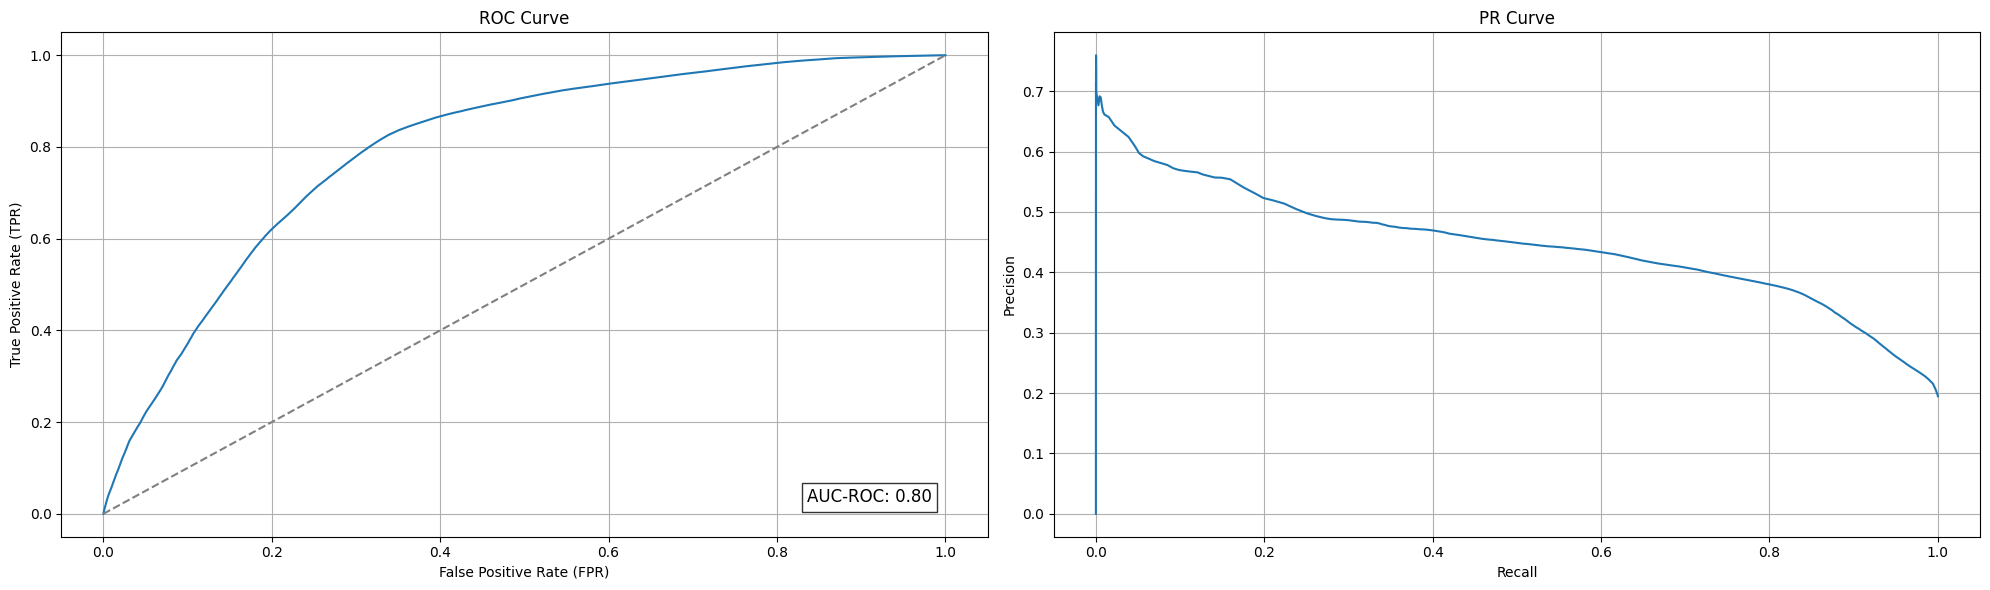

In [41]:
# Рассчитываем AUC ROC
auc_roc = calculate_auc_roc(model=cv_model,
                            test_data=test_df,
                            label_col=label_col)
pd_dataframe = calculate_metrics(model=cv_model,
                                 test_data=test_df,
                                 label_col=label_col)
print(f"AUC ROC: {auc_roc:.4f}")
plot_roc_pr_curves(pd_dataframe, auc_roc)

Определим вероятность -- границу разделения, при которой `Recall` не меньше 60 %.

In [42]:
threshold_probability = pd_dataframe[pd_dataframe['TPR'] >= 0.60]['probability'].max()
print(f"Вероятность -- граница разделения, при которой TPR не меньше 60%: "
      f"{threshold_probability:.2f}")

Вероятность -- граница разделения, при которой TPR не меньше 60%: 0.61


Рассчитаем метрики на тестовом датасете повторно, с учетом вычисленного `threshold` для вероятности. `setThresholds` фиксирует правило принятия решения: объект положительного класса относится к положительному классу, если его вероятность не ниже выбранного уровня.

In [43]:
cv_model.bestModel.stages[-1].setThresholds([1 - threshold_probability,
                                             threshold_probability])
test_df_predictions = cv_model.transform(test_df)
metrics = evaluate_model(test_df_predictions, label_col)
print(f"Metrics: {metrics}")

Metrics: {'precision': 0.43319928133455504, 'recall': 0.601829325037557, 'f1': 0.5037774405214829}


#### Выводы по части 2

**Баланс классов и его цена.** Положительных записей (`Severity >= 3`) в датасете 1 504 047 из 7 728 394 -- 19.47 %. Стратифицированное разделение 80/20 дало обучающую выборку, в котором oversampling развернул каждый положительный пример в 4 копии: 4 812 684 против 4 980 037 отрицательных, соотношение 1:1.03. Тестовая выборка (1 545 186 строк) осталась небалансной, и именно это объясняет главный парадокс ниже.

**Подбор параметров.** Полная сетка $3 \times 3$ при пяти фолдах стоила бы 3.6 ч -- оценку даёт замер одного обучения конвейера (285 сек) прямо в ноутбуке. Ограниченной сеткой `maxDepth` [4, 6] при 50 деревьях (10 обучений) удалось показать направление: глубина 6 даёт $CV\ AUC\ ROC = 0.7976$ против 0.7799 при глубине 4, то есть один дополнительный уровень дерева добавляет 1.8 процентного пункта качества ранжирования. `maxBins = 64` здесь не свободный выбор, а требование: у признака `State` 52 уровня, и при значении по умолчанию (32) `DecisionTree` отказывается строить модель. Тестовая $AUC\ ROC = 0.7970$ совпадает с кросс-валидационной -- фолды не переоптимизированы.

**Порог важнее модели.** При пороге 0.5 получены $Precision = 0.3867$, $Recall = 0.7767$, $F1 = 0.5163$. Модель ловит 77.7 % тяжёлых происшествий, но 61 % её срабатываний -- ложные: она обучена на сбалансных данных и выдаёт «оптимистичные» вероятности, а проверяется на реальном распределении, где 80.53 % записей -- отрицательные. Отсюда и отказ от $Accuracy$: тривиальный предсказатель «всегда 0» даёт 80.53 %, то есть выше, чем у модели, и при этом бесполезен; тривиальный «всегда 1» даёт $Precision = 0.1947$ -- ровно долю миноритарного класса.

Сдвиг порога до 0.61 (условие $Recall \ge 60\ %$) меняет решение: $Precision = 0.4332$ (+4.7 п.п.), $Recall = 0.6018$ (−17.5 п.п.), $F1 = 0.5038$. $F1$ при этом чуть падает, и это закономерно: он максимален вблизи естественной точки равновесия модели, тогда как требование задачи -- нижняя граница полноты. Цена поиска тяжёлого происшествия -- рост пропущенных примеров примерно на 17 % от всех тяжёлых.

**Важность признаков и её интерпретация.** Топ-5 признаков даёт 0.8238 суммарной важности, из них `Distance(mi)` -- 0.3047 и `Duration_min` -- 0.2557. Вдвоём они переносят более половины всего сигнала, и это надо понимать буквально: оба признака описывают уже завершившееся происшествие (протяжённость перекрытия и его длительность), а `Duration_min` к тому же является мишенью части 1. Для производственной модели раннего предупреждения эти два признака пришлось бы убрать -- тогда остаётся реальная предиктивная основа: `Traffic_Signal` (0.1024), `Weather_Condition` (0.0851), `Crossing` (0.0759), `Wind_Chill(F)` (0.0678), то есть инфраструктура перекрёстка и погода.

**Итог.** Задача классификации тяжести на этом датасете решается: $AUC\ ROC = 0.7970$ против 0.5 у тривиального ранжирования, и порог позволяет выровнять $Precision$/$Recall$ под требование заказчиков. На контрасте с частью 1, где линейная регрессия длительности дала $R^2 = 0.0472$, видно, что узкое место -- не объём данных и не конвейер признаков, а слабая предсказуемость самой длительности по доступным признакам.

Не забываем завершать `Spark`-сессию.

In [44]:
spark.catalog.clearCache()
spark.stop()